# blindtrix_v1: raw ZIP to clean classification source

**Purpose:** keep all readable, correctly annotated, one-banknote representatives from this source after the frozen bbox gate and natural-context crop.

This notebook only cleans one source. It does not balance classes, create final train/dev/test splits, or train a model.


## 1. Imports and global configuration



In [1]:
from pathlib import Path
from zipfile import ZipFile
from collections import Counter
from datetime import datetime
from PIL import Image
from IPython.display import display
import pandas as pd
import yaml
import hashlib
import math
import re
import io
import matplotlib.pyplot as plt

In [2]:
DATASET_ID = "blindtrix_v1"
RAW_ZIP = Path.home() / "Downloads" / 'Money_VN_Regconization 2.v1i.yolov5pytorch.zip'
OUTPUT_ROOT = Path(r"C:\CS231_RAW_NOTEBOOK_RUNS\blindtrix_v1_simple")
RUN_DIR = OUTPUT_ROOT / datetime.now().strftime("%Y%m%d_%H%M%S_%f")
RUN_ROOT = RUN_DIR
OUTPUT = RUN_ROOT
RUN_ROOT.mkdir(parents=True, exist_ok=True)

TARGET_CLASSES = ["10000", "20000", "50000", "100000", "200000", "500000"]
BBOX_MIN_SHORT_SIDE = 120
CONTEXT_RATIO = 0.20

assert RAW_ZIP.is_file(), f"Không tìm thấy ZIP: {RAW_ZIP}"
archive = ZipFile(RAW_ZIP)
members = set(archive.namelist())

print("Dataset:", 'blindtrix_v1')
print("ZIP:", RAW_ZIP)
print("Run output:", OUTPUT)

Dataset: blindtrix_v1
ZIP: C:\Users\Nguyen\Downloads\Money_VN_Regconization 2.v1i.yolov5pytorch.zip
Run output: C:\CS231_RAW_NOTEBOOK_RUNS\blindtrix_v1_simple\20261026_002923_926824


## 2. Open the ZIP, read data.yaml, and inventory the export



In [3]:
# Tìm data.yaml trong ZIP thay vì giả định nó luôn nằm ở root.
yaml_candidates = [m for m in sorted(members) if m == "data.yaml" or m.endswith("/data.yaml")]
assert yaml_candidates, "Không tìm thấy data.yaml trong ZIP"
config_member = yaml_candidates[0]
config = yaml.safe_load(archive.read(config_member).decode("utf-8-sig"))

names = config["names"]
if isinstance(names, list):
    class_names = {i: str(name) for i, name in enumerate(names)}
else:
    class_names = {int(k): str(v) for k, v in names.items()}
class_to_vnd = {class_id: re.sub(r"\D", "", name) for class_id, name in class_names.items()}

class_table = pd.DataFrame([
    {
        "class_id": class_id,
        "raw_class_name": class_names[class_id],
        "normalized": class_to_vnd[class_id],
        "used": class_to_vnd[class_id] in TARGET_CLASSES,
    }
    for class_id in sorted(class_names)
])
display(class_table)

image_members = [
    m for m in sorted(members)
    if "/images/" in m and Path(m).suffix.lower() in {".jpg", ".jpeg", ".png"}
]
assert image_members, "Không tìm thấy ảnh trong các thư mục images/ của ZIP"

missing_labels = [
    m for m in image_members
    if m.replace("/images/", "/labels/").rsplit(".", 1)[0] + ".txt" not in members
]
split_counts = Counter(m.split("/images/")[0].split("/")[-1] for m in image_members)

print("data.yaml:", config_member)
print("Raw image files:", len(image_members))
print("Original split counts:", dict(split_counts))
print("Missing label files:", len(missing_labels))

,class_id,raw_class_name,normalized,used
0,0,1000,1000,False
1,1,10000,10000,True
2,2,100000,100000,True
3,3,2000,2000,False
4,4,20000,20000,True
5,5,200000,200000,True
6,6,5000,5000,False
7,7,50000,50000,True
8,8,500000,500000,True


data.yaml: data.yaml
Raw image files: 8927
Original split counts: {'test': 375, 'train': 8088, 'valid': 464}
Missing label files: 0


## 3. Common helper functions and source metadata



In [4]:
def normalize_class_names(names):
    """Trả về dict {class_id: class_name} cho cả YAML dạng list hoặc dict."""
    if isinstance(names, list):
        return {i: str(name) for i, name in enumerate(names)}
    if isinstance(names, dict):
        return {int(k): str(v) for k, v in names.items()}
    raise TypeError(f"data.yaml names có kiểu không hỗ trợ: {type(names)}")


def denomination_from_name(class_name):
    """Chuẩn hóa tên class như '20 000 VND', '20.000', '20000' -> '20000'."""
    digits = re.sub(r"\D", "", str(class_name))
    return digits


def label_for(image_member):
    label_name = image_member.replace("/images/", "/labels/")
    return label_name.rsplit(".", 1)[0] + ".txt"


def source_name(member):
    """Bỏ hậu tố Roboflow .rf.<hash> và hậu tố _jpg/_png/_jpeg để gom cùng ảnh nguồn."""
    name = re.sub(r"\.rf\.[0-9a-f]+$", "", Path(member).stem, flags=re.I)
    return re.sub(r"_(jpg|png|jpeg)$", "", name, flags=re.I)


def original_split(member):
    prefix = member.split("/images/")[0]
    return prefix.split("/")[-1] if prefix else ""


def read_boxes(label_member):
    """Đọc YOLO bbox; annotation lỗi -> trả [] để ảnh không đi qua gate."""
    if label_member not in members:
        return []

    boxes = []
    text = archive.read(label_member).decode("utf-8-sig")
    for line in text.splitlines():
        values = line.split()
        if len(values) != 5:
            return []
        try:
            class_id = int(values[0])
            cx, cy, bw, bh = map(float, values[1:])
        except ValueError:
            return []

        if class_id not in class_to_vnd:
            return []
        if not all(math.isfinite(v) for v in (cx, cy, bw, bh)):
            return []
        if not (0 <= cx <= 1 and 0 <= cy <= 1 and 0 < bw <= 1 and 0 < bh <= 1):
            return []

        boxes.append({
            "raw_label": class_to_vnd[class_id],
            "cx": cx, "cy": cy, "bw": bw, "bh": bh,
        })
    return boxes


def pixel_bbox(row):
    """YOLO normalized bbox -> pixel bbox trên available source export."""
    width, height = int(row["width"]), int(row["height"])
    cx, cy, bw, bh = float(row["cx"]), float(row["cy"]), float(row["bw"]), float(row["bh"])

    left = cx - bw / 2
    top = cy - bh / 2
    right = cx + bw / 2
    bottom = cy + bh / 2

    return (
        max(0, math.floor(left * width)),
        max(0, math.floor(top * height)),
        min(width, math.ceil(right * width)),
        min(height, math.ceil(bottom * height)),
    )


def context_box(box, width, height, margin=CONTEXT_RATIO):
    """Mở bbox thêm 20% kích thước bbox ở mỗi phía, rồi clamp vào ảnh."""
    x1, y1, x2, y2 = box
    box_w, box_h = x2 - x1, y2 - y1
    return (
        max(0, round(x1 - margin * box_w)),
        max(0, round(y1 - margin * box_h)),
        min(width, round(x2 + margin * box_w)),
        min(height, round(y2 + margin * box_h)),
    )

## 4. Build one valid representative per source



In [5]:
records = []

for member in image_members:
    label_member = label_for(member)
    boxes = read_boxes(label_member)

    try:
        raw_bytes = archive.read(member)
        with Image.open(io.BytesIO(raw_bytes)) as image:
            image.load()
            width, height = image.size
        readable = True
    except Exception:
        width, height, readable = 0, 0, False

    exactly_one_target = (
        readable
        and len(boxes) == 1
        and boxes[0]["raw_label"] in TARGET_CLASSES
    )

    row = {
        "member": member,
        "annotation_member": label_member,
        "original_split": original_split(member),
        "source_name": source_name(member),
        "path_order": member.replace("/", "\\"),
        "width": width,
        "height": height,
        "pixel_area": width * height,
        "readable": readable,
        "exactly_one_target": exactly_one_target,
        "is_variant": bool(re.search(r"\.rf\.[0-9a-f]+$", Path(member).stem, flags=re.I)),
    }
    row.update(
        boxes[0] if len(boxes) == 1
        else {"raw_label": "", "cx": 0.0, "cy": 0.0, "bw": 0.0, "bh": 0.0}
    )
    records.append(row)

all_images = pd.DataFrame(records)

# Một source_name có thể có nhiều export/augmentation copy.
# Ưu tiên: ảnh hợp lệ -> bản không mang hậu tố .rf nếu có -> ảnh nhiều pixel hơn -> đường dẫn ổn định.
ranked = all_images.sort_values(
    ["exactly_one_target", "is_variant", "pixel_area", "path_order"],
    ascending=[False, True, False, True],
)
representatives = ranked.drop_duplicates("source_name", keep="first").copy()
pool = representatives[representatives["exactly_one_target"]].copy()
pool = pool.sort_values("path_order").reset_index(drop=True)

all_images.to_csv(OUTPUT / "01_ALL_RAW_IMAGES.csv", index=False)
representatives.to_csv(OUTPUT / "02_SOURCE_REPRESENTATIVES.csv", index=False)
pool.to_csv(OUTPUT / "03_VALID_ONE_BANKNOTE_POOL.csv", index=False)

print("Raw exported image files:", len(all_images))
print("Unique source groups:", len(representatives))
print("Valid six-class one-bbox representatives:", len(pool))
display(pool.groupby("raw_label").size().reindex(TARGET_CLASSES, fill_value=0).to_frame("valid_before_bbox_gate"))

Raw exported image files: 8927
Unique source groups: 3496
Valid six-class one-bbox representatives: 2000


,valid_before_bbox_gate
raw_label,
10000,354
20000,359
50000,295
100000,276
200000,357
500000,359


## 5. Apply only verified corrections and removals

No verified corrections or removals are recorded for this source.


In [6]:
CORRECT_LABEL_BY_SHA256 = {}
REMOVE_BY_SHA256 = {}
verified_relabels = 0
verified_removals = 0
print("Verified relabels:", verified_relabels)
print("Verified removals:", verified_removals)

Verified relabels: 0
Verified removals: 0


## 6. Apply the frozen bbox threshold



In [7]:
# 120 px là threshold trên available export, KHÔNG phải native-resolution threshold.
bboxes = []
short_sides = []
for row in pool.to_dict("records"):
    bbox = pixel_bbox(row)
    bboxes.append(bbox)
    short_sides.append(min(bbox[2] - bbox[0], bbox[3] - bbox[1]))

pool["bbox"] = bboxes
pool["bbox_short_side_px"] = short_sides

below_120 = pool[pool["bbox_short_side_px"] < BBOX_MIN_SHORT_SIDE].copy()
selected = pool[pool["bbox_short_side_px"] >= BBOX_MIN_SHORT_SIDE].copy().reset_index(drop=True)

below_120.to_csv(OUTPUT / "04_BELOW_120PX_REMOVALS.csv", index=False)
selected.to_csv(OUTPUT / "05_SELECTED_BEFORE_CROP.csv", index=False)

print("Removed because bbox short-side < BBOX_MIN_SHORT_SIDE px:", len(below_120))
print("Final kept before crop export:", len(selected))
display(selected.groupby("raw_label").size().reindex(TARGET_CLASSES, fill_value=0).to_frame("kept_after_bbox_gate"))

Removed because bbox short-side < BBOX_MIN_SHORT_SIDE px: 2
Final kept before crop export: 1998


,kept_after_bbox_gate
raw_label,
10000,354
20000,359
50000,293
100000,276
200000,357
500000,359


## 7. Crop with 20% context



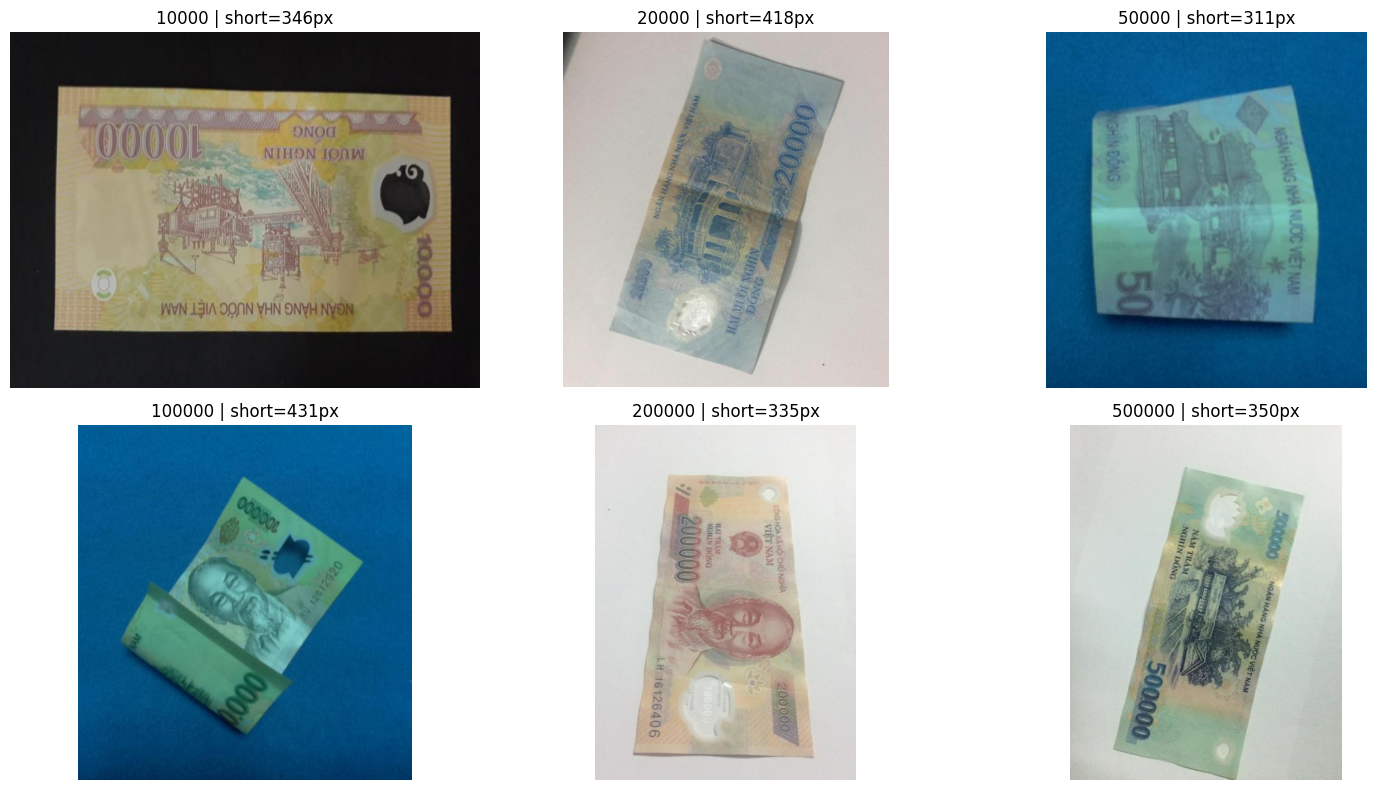

In [8]:
# Preview tối đa 1 ảnh/class để người chạy kiểm tra logic crop.
preview_rows = []
for label in TARGET_CLASSES:
    group = selected[selected["raw_label"] == label]
    if not group.empty:
        preview_rows.append(group.iloc[0].to_dict())

if preview_rows:
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    axes = axes.ravel()
    for ax in axes:
        ax.axis("off")
    for ax, row in zip(axes, preview_rows):
        with Image.open(io.BytesIO(archive.read(row["member"]))) as image:
            image = image.convert("RGB")
            crop_box = context_box(row["bbox"], image.width, image.height)
            crop = image.crop(crop_box)
        ax.imshow(crop)
        ax.set_title(f"{row['raw_label']} | short={row['bbox_short_side_px']}px")
        ax.axis("off")
    plt.tight_layout()
    plt.show()

## 8. Export kept samples and write the manifest



In [9]:
DATA_OUT = OUTPUT / "BLINDTRIX_V1_CLEAN"
DATA_OUT.mkdir(parents=True, exist_ok=True)

manifest_rows = []
class_indices = Counter()

rows_to_save = selected.sort_values(["raw_label", "source_name", "path_order"])
for row in rows_to_save.to_dict("records"):
    label = str(row["raw_label"])
    class_indices[label] += 1
    raw_bytes = archive.read(row["member"])

    with Image.open(io.BytesIO(raw_bytes)) as image:
        image = image.convert("RGB")
        crop_box = context_box(row["bbox"], image.width, image.height, margin=CONTEXT_RATIO)
        crop = image.crop(crop_box)

    filename = f"BLINDTRIX_{label}_{class_indices[label]:05d}.png"
    relative_path = f"{label}/{filename}"
    target = DATA_OUT / relative_path
    target.parent.mkdir(parents=True, exist_ok=True)
    crop.save(target, format="PNG", optimize=False)

    manifest_rows.append({
        "relative_path": relative_path,
        "dataset_id": "blindtrix_v1",
        "source_name": row["source_name"],
        "source_archive_member": row["member"],
        "annotation_member": row["annotation_member"],
        "original_split": row["original_split"],
        "capture_group": row["source_name"],
        "raw_label": label,
        "denomination": label,
        "width": int(row["width"]),
        "height": int(row["height"]),
        "bbox_x1": int(row["bbox"][0]),
        "bbox_y1": int(row["bbox"][1]),
        "bbox_x2": int(row["bbox"][2]),
        "bbox_y2": int(row["bbox"][3]),
        "bbox_short_side_px": int(row["bbox_short_side_px"]),
        "crop_x1": int(crop_box[0]),
        "crop_y1": int(crop_box[1]),
        "crop_x2": int(crop_box[2]),
        "crop_y2": int(crop_box[3]),
        "crop_width": int(crop.width),
        "crop_height": int(crop.height),
        "source_image_sha256": hashlib.sha256(raw_bytes).hexdigest(),
        "final_crop_sha256": hashlib.sha256(target.read_bytes()).hexdigest(),
    })

manifest = pd.DataFrame(manifest_rows)
manifest.to_csv(DATA_OUT / "manifest.csv", index=False)

print("Clean source folder:", DATA_OUT)
print("Manifest:", DATA_OUT / "manifest.csv")
display(manifest.groupby("denomination").size().reindex(TARGET_CLASSES, fill_value=0).to_frame("final_kept"))

Clean source folder: C:\CS231_RAW_NOTEBOOK_RUNS\blindtrix_v1_simple\20261026_002923_926824\BLINDTRIX_V1_CLEAN
Manifest: C:\CS231_RAW_NOTEBOOK_RUNS\blindtrix_v1_simple\20261026_002923_926824\BLINDTRIX_V1_CLEAN\manifest.csv


,final_kept
denomination,
10000,354
20000,359
50000,293
100000,276
200000,357
500000,359


## 9. Final source-run audit



In [10]:
# Tất cả các con số dưới đây được tính lại từ manifest và PNG vừa xuất.
manifest = result if "result" in globals() else manifest
label_col = "final_label" if "final_label" in manifest.columns else "denomination"
png_files = list(DATA_OUT.rglob("*.png"))
unreadable_png = 0
for path in png_files:
    try:
        with Image.open(path) as image:
            image.verify()
    except Exception:
        unreadable_png += 1

if "before_scale_filter" in globals():
    valid_before_bbox = int(before_scale_filter)
else:
    valid_before_bbox = len(pool)
removed_by_bbox = valid_before_bbox - len(manifest)
class_counts = manifest.groupby(label_col).size().reindex(TARGET_CLASSES, fill_value=0).to_dict()
invalid_labels = sorted(set(manifest[label_col].astype(str)) - set(TARGET_CLASSES))
path_label_mismatch = sum(
    str(row["relative_path"]).replace("\\", "/").split("/")[0] != str(row[label_col])
    for _, row in manifest.iterrows()
)
min_bbox = int(manifest["bbox_short_side_px"].astype(int).min()) if len(manifest) else 0
duplicate_source = int(manifest["source_name"].duplicated().sum())
duplicate_path = int(manifest["relative_path"].duplicated().sum())
relabeled = len(corrections_found) if "corrections_found" in globals() else int(globals().get("verified_relabels", 0))
removed_by_review = int(globals().get("verified_removals", 0))
checks_pass = (
    len(manifest) == len(png_files)
    and unreadable_png == 0
    and duplicate_source == 0
    and duplicate_path == 0
    and invalid_labels == []
    and path_label_mismatch == 0
    and min_bbox >= BBOX_MIN_SHORT_SIDE
)
source_run_status = "PASS" if checks_pass else "HOLD"

summary_lines = [
    f"DATASET_ID = {DATASET_ID}",
    f"RAW_IMAGES = {len(all_images)}",
    f"SOURCE_GROUPS = {len(representatives)}",
    f"VALID_BEFORE_BBOX = {valid_before_bbox}",
    f"VERIFIED_RELABELS = {relabeled}",
    f"VERIFIED_REMOVALS = {removed_by_review}",
    f"BBOX_LT_120_REMOVED = {removed_by_bbox}",
    f"FINAL_KEPT = {len(manifest)}",
    f"FINAL_CLASS_COUNTS = {class_counts}",
    f"MANIFEST_ROWS = {len(manifest)}",
    f"PNG_COUNT = {len(png_files)}",
    f"DUPLICATE_SOURCE_NAME = {duplicate_source}",
    f"DUPLICATE_RELATIVE_PATH = {duplicate_path}",
    f"INVALID_FINAL_LABELS = {invalid_labels}",
    f"PATH_LABEL_MISMATCH = {path_label_mismatch}",
    f"UNREADABLE_EXPORTED_PNG = {unreadable_png}",
    f"MIN_BBOX_SHORT_SIDE_PX = {min_bbox}",
    f"OUTPUT_ROOT = {DATA_OUT}",
    f"SOURCE_RUN_STATUS = {source_run_status}",
]
summary_text = "\n".join(summary_lines)
(RUN_ROOT / "RUN_SUMMARY.txt").write_text(summary_text, encoding="utf-8")
print(summary_text)
assert source_run_status == "PASS", "Source output audit did not pass; preserve run outputs for review."


DATASET_ID = blindtrix_v1
RAW_IMAGES = 8927
SOURCE_GROUPS = 3496
VALID_BEFORE_BBOX = 2000
VERIFIED_RELABELS = 0
VERIFIED_REMOVALS = 0
BBOX_LT_120_REMOVED = 2
FINAL_KEPT = 1998
FINAL_CLASS_COUNTS = {'10000': 354, '20000': 359, '50000': 293, '100000': 276, '200000': 357, '500000': 359}
MANIFEST_ROWS = 1998
PNG_COUNT = 1998
DUPLICATE_SOURCE_NAME = 0
DUPLICATE_RELATIVE_PATH = 0
INVALID_FINAL_LABELS = []
PATH_LABEL_MISMATCH = 0
UNREADABLE_EXPORTED_PNG = 0
MIN_BBOX_SHORT_SIDE_PX = 125
OUTPUT_ROOT = C:\CS231_RAW_NOTEBOOK_RUNS\blindtrix_v1_simple\20261026_002923_926824\BLINDTRIX_V1_CLEAN
SOURCE_RUN_STATUS = PASS
